In [50]:
import cv2 as cv
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import os
import numpy as np
import pandas as pd

# Functions

In [51]:
def import_sequence(directory, channels, suffix_len=4, ext_len=3):
    imgs = {}

    for channel in channels.values():
        imgs[channel] = []

    for file in os.listdir(directory):
        f = os.path.join(directory, file)
        if os.path.isdir(f) or not f.endswith('.tif'):
            continue
        channel = channels[file[-1*(suffix_len+ext_len+1):-1*(ext_len+1)]]
        imgs[channel].append(cv.imread(f, 0))

    return imgs

In [52]:
def stack_2d(imgs, mode='max'):
    imgs_stacked = {}
    if type(mode) is list and len(mode) == len(imgs.keys()):
        for i, channel in enumerate(imgs.keys()):
            if mode[i]=='max':
                stacked = np.zeros_like(imgs[channel][0])
                for image in imgs[channel]:
                    stacked = np.maximum(stacked, image)
                imgs_stacked[channel] = stacked
            elif mode[i]=='average':
                imgs_stacked[channel] = np.mean(np.array([imgs[channel]])[0], axis=0).astype(np.uint8)
            else:
                print('i dont know what '+mode+' means')
    elif type(mode) is str:
        if mode=='max':
            for channel in imgs.keys():
                stacked = np.zeros_like(imgs[channel][0])
                for image in imgs[channel]:
                    stacked = np.maximum(stacked, image)
                imgs_stacked[channel] = stacked
        elif mode=='average':
            for channel in imgs.keys():
                imgs_stacked[channel] = np.mean(np.array([imgs[channel]])[0], axis=0).astype(np.uint8)
        else:
            print('i dont know what '+mode+' means')
    else:
        print('weird type for mode')

    return imgs_stacked

In [53]:
def plot_channels_split(imgs_stacked, cmaps, figsize=(15, 5), plot=True, title=''):
    fig, axs = plt.subplots(1, 4, figsize=figsize)
    for i, channel in enumerate(imgs_stacked.keys()):
        axs[i].imshow(imgs_stacked[channel], cmap=cmaps[channel], vmin=0,vmax=255)
        axs[i].set_title(channel)
        axs[i].set_axis_off()
    fig.suptitle(title)
    plt.show()
    if plot:
        plt.show()
    else:
        return fig

In [54]:
def plot_image(img, cmap='gray', title='', figsize=(10, 10), plot=True):
    plt.figure(figsize=figsize)
    plt.imshow(img, cmap=cmap, vmin=0,vmax=255)
    plt.title(title)
    plt.axis('off')
    plt.show()

# Testing on one image

## Change your channels here

In [102]:
test_image_file = '052726_Reimage/052725_mouse7_reimaging_slide49_MBP_center_3' # image file to test

In [103]:
calc_stains = ['MBP','GAL1'] # stains to calculate relative area (all stains but reference)
reference_stain = 'MHC' # the stain to use as the reference for ROI
#stains = [reference_stain] + calc_stains # combines both for a list of all stains
stains = ['DAPI', 'MHC', 'MBP', 'GAL1']

In [104]:
# change these colors if you want - (0,0,0) are red, green, and blue values respectively from 0-1
channel_cmaps = {
    'DAPI':LinearSegmentedColormap.from_list("Custom", [(0,0,0), (0,0,1)], N=256), # blue
    'MHC':LinearSegmentedColormap.from_list("Custom", [(0,0,0), (1,1,0)], N=256),  # yellow
    'MBP':LinearSegmentedColormap.from_list("Custom", [(0,0,0), (1,0,0)], N=256), # red
    'GAL1':LinearSegmentedColormap.from_list("Custom", [(0,0,0), (0,1,0)], N=256)  # green
    }

In [105]:
channels = {'ch0'+str(i):stain for i, stain in enumerate(stains)}
channels # assigns channels to stains - make sure these match what is in your data

{'ch00': 'DAPI', 'ch01': 'MHC', 'ch02': 'MBP', 'ch03': 'GAL1'}

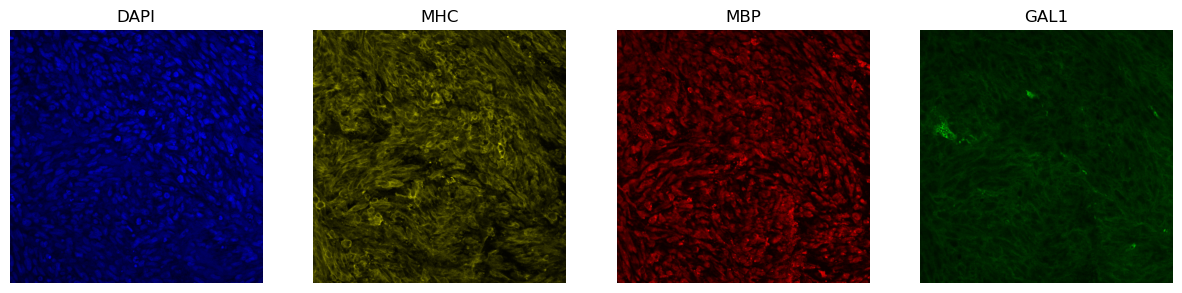

In [106]:
test_img = stack_2d(import_sequence(test_image_file, channels))
plot_channels_split(test_img, channel_cmaps)

## Change the thresholds here

In [107]:
threshold = {}
threshold['DAPI'] = 130
threshold['MHC'] = 42
threshold['MBP'] = 60
threshold['GAL1'] = 37

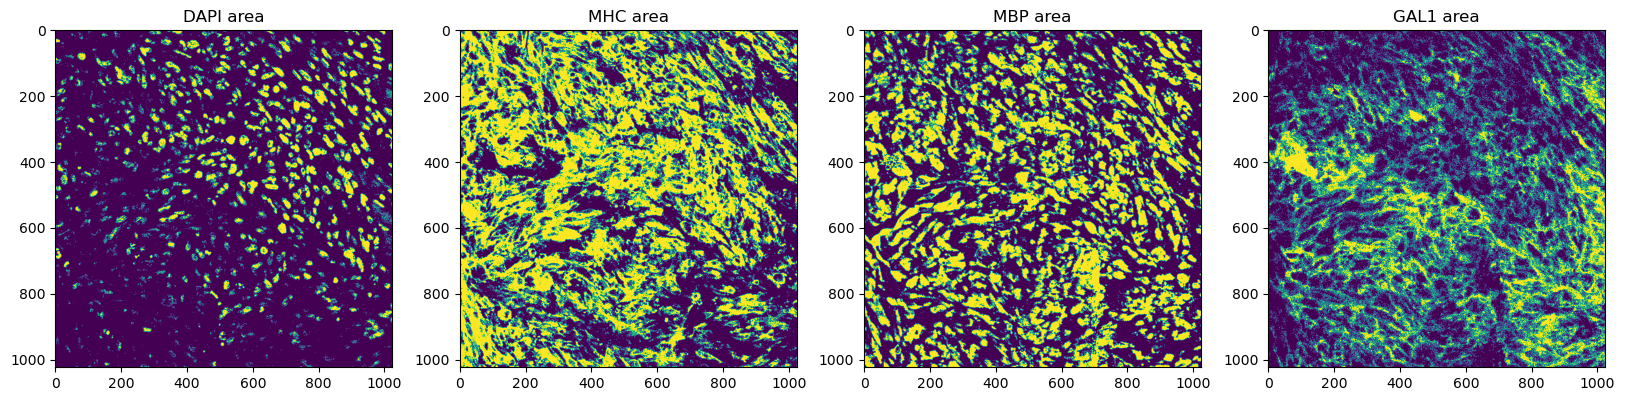

In [108]:
fig, axs = plt.subplots(1, 4, figsize=(20, 19))

for i, stain in enumerate(stains):
    axs[i].imshow(test_img[stain] > threshold[stain])
    axs[i].set_title(stain+' area')

plt.show()

In [123]:
def area_quant(img, threshold, ref='MHC', display=False, title=None):
    if display: # plotting
        _, axs = plt.subplots(2, len(stains), figsize=(len(stains)*4-1, 7)) 
        for i, stain in enumerate(stains): # plot each stain alone
            axs[0, i].imshow(img[stain], cmap=channel_cmaps[stain], vmin=0,vmax=255)
            axs[0, i].set_title(stain)
            axs[0, i].set_axis_off()
        axs[1, 0].imshow(cv.merge([img[stain] for stain in stains[::-1]])) # plot stains combined
        axs[1, 0].set_axis_off()
        axs[1, 0].set_title('all')
    
    areas = {}
    for i, stain in enumerate(calc_stains): # loop through stains
        if stain != ref:
            if stain == 'GAL1':
                roi = img[reference_stain] > threshold[reference_stain] # coordinates of each pixel where MHC is above the threshold
                #vessel = img['MBP'] > threshold['<BP'] # coordinates where pixel where <BP is above the threshold
                vessel_area = np.sum(img['MBP'][roi] > threshold['MBP']) # where MBP is above threshold within our ROI
                stain_area = np.sum(img[stain][roi] > threshold[stain]) # where our stain is above the threshold within our ROI
                areas[stain] = np.sum((img['MBP'][roi] > threshold['MBP']) & (img[stain][roi] > threshold[stain]))/stain_area #perecent of gal1 localized to myelin
                #areas[stain] = np.sum((img['MBP'][roi] > threshold['MBP']) & (img[stain][roi] > threshold[stain]))/vessel_area #perecent of myelin that have gal1 expression
                #areas[stain] = stain_area/np.sum(roi) #gal1 area/ MHC area
            else:
                roi = img[reference_stain] > threshold[reference_stain] # coordinates of each pixel where LAMA is above the threshold
                stain_area = np.sum(img[stain][roi] > threshold[stain]) # where our stain is above the threshold within our ROI
                areas[stain] = stain_area/np.sum(roi) # our metric defined above

    if display:
        if title != None:
            plt.suptitle(title)
        plt.show()

    return areas

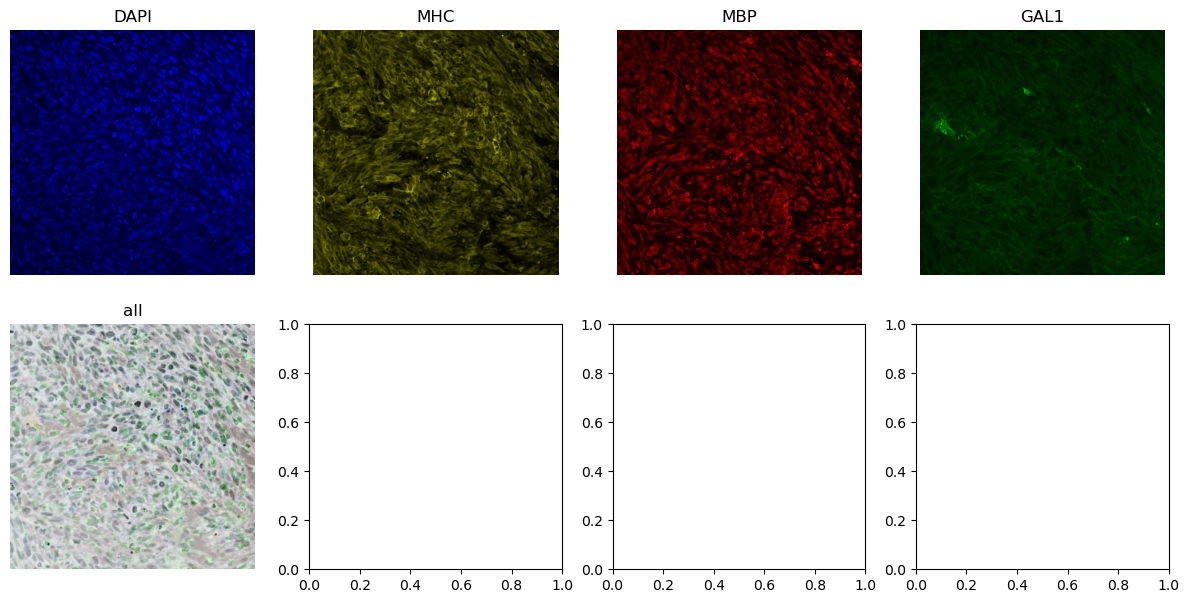

{'MBP': np.float64(0.4626699366488809),
 'GAL1': np.float64(0.44063268841624087)}

In [124]:
area_quant(test_img, threshold, display=True)

# Analysis on all images

In [125]:
# makes a table (dataframe) to store all our data
df = pd.DataFrame(
    columns=['sample']+calc_stains
    )
df.set_index('sample', inplace=True)
df

,MBP,GAL1
sample,,


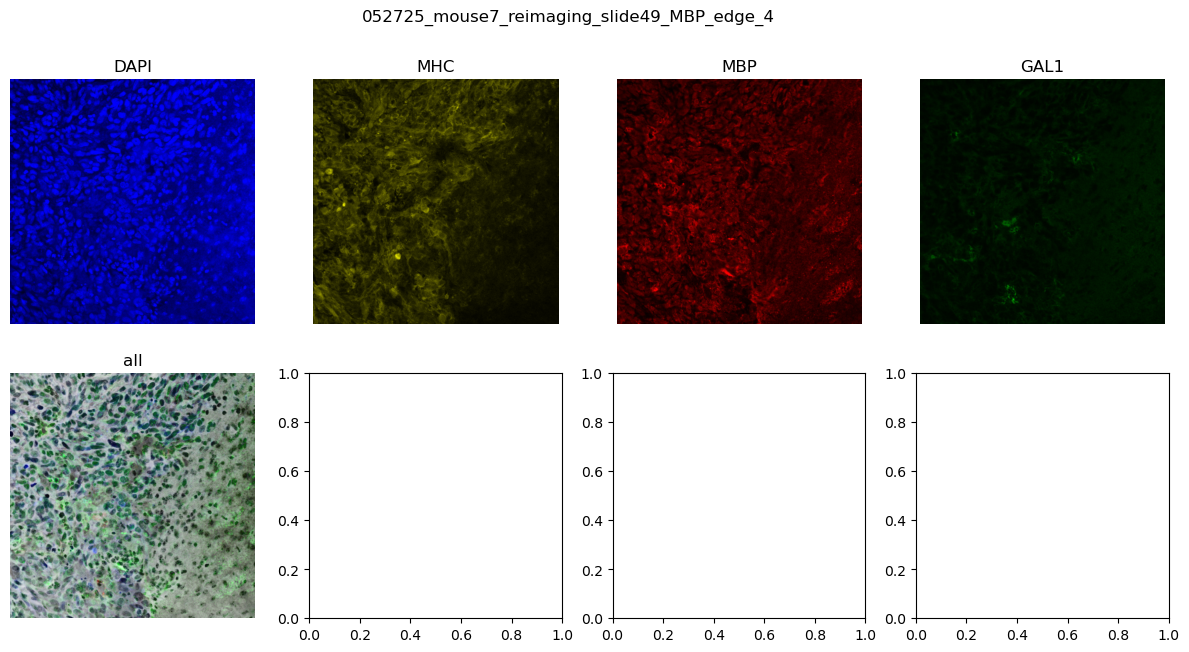

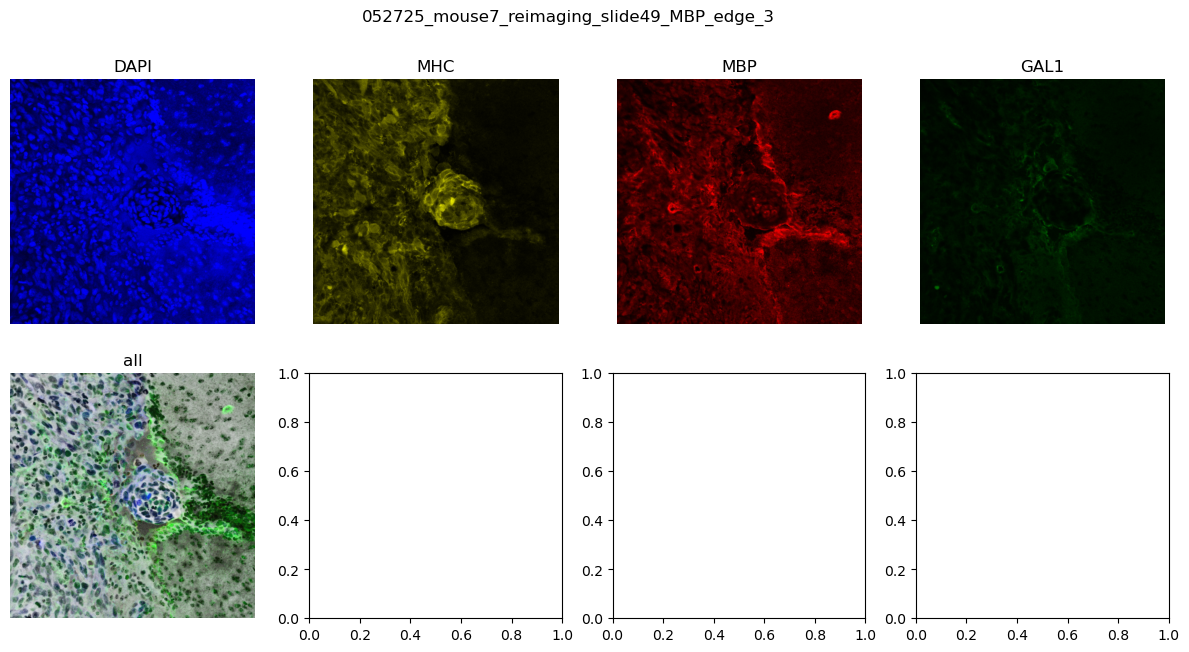

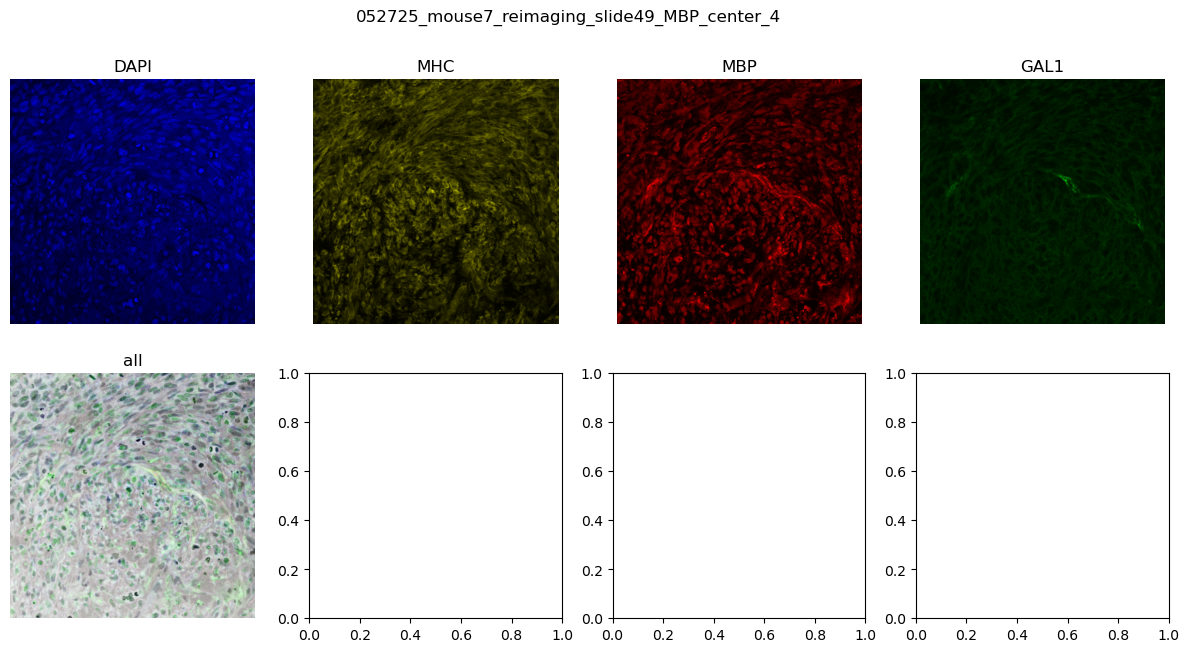

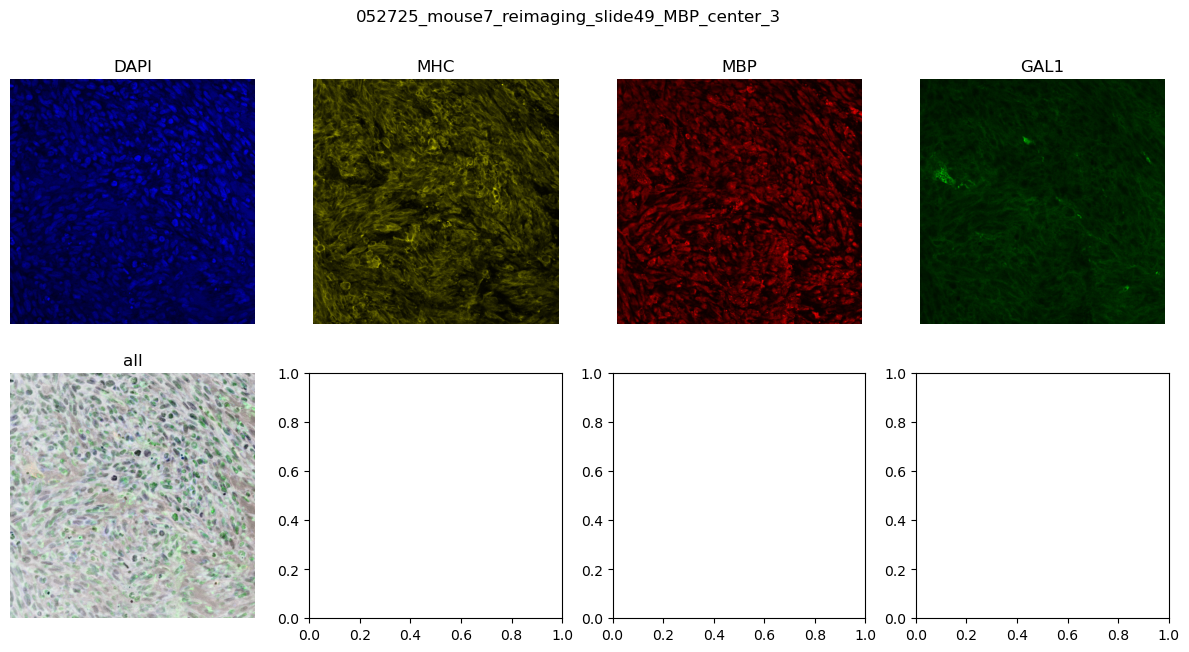

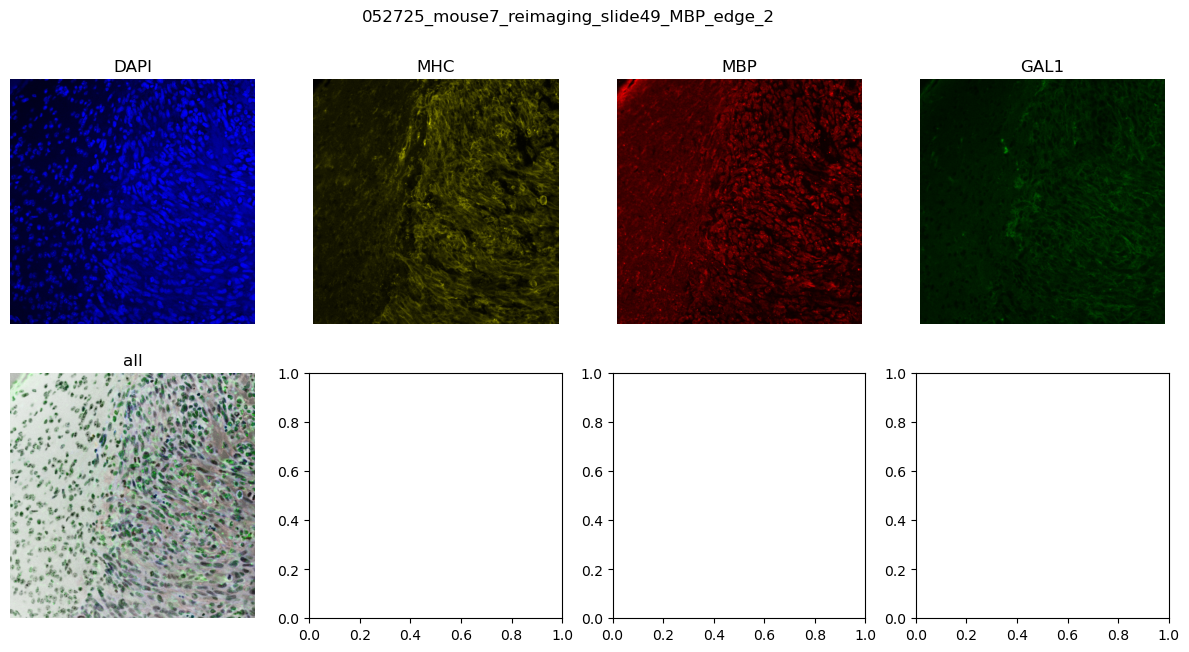

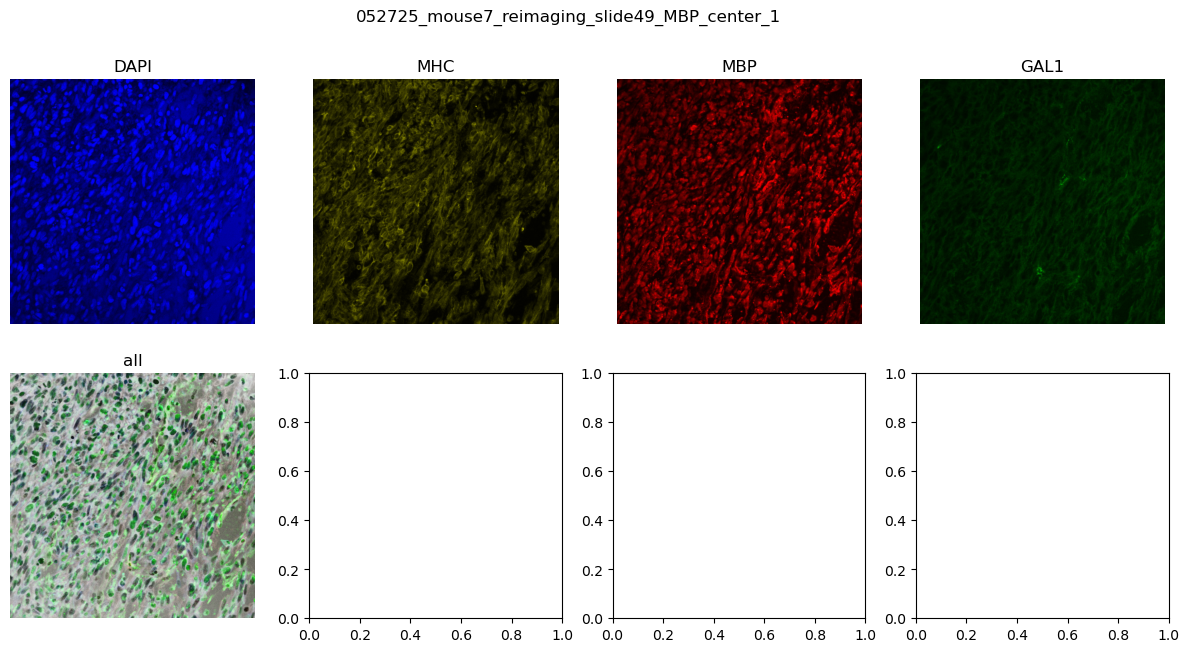

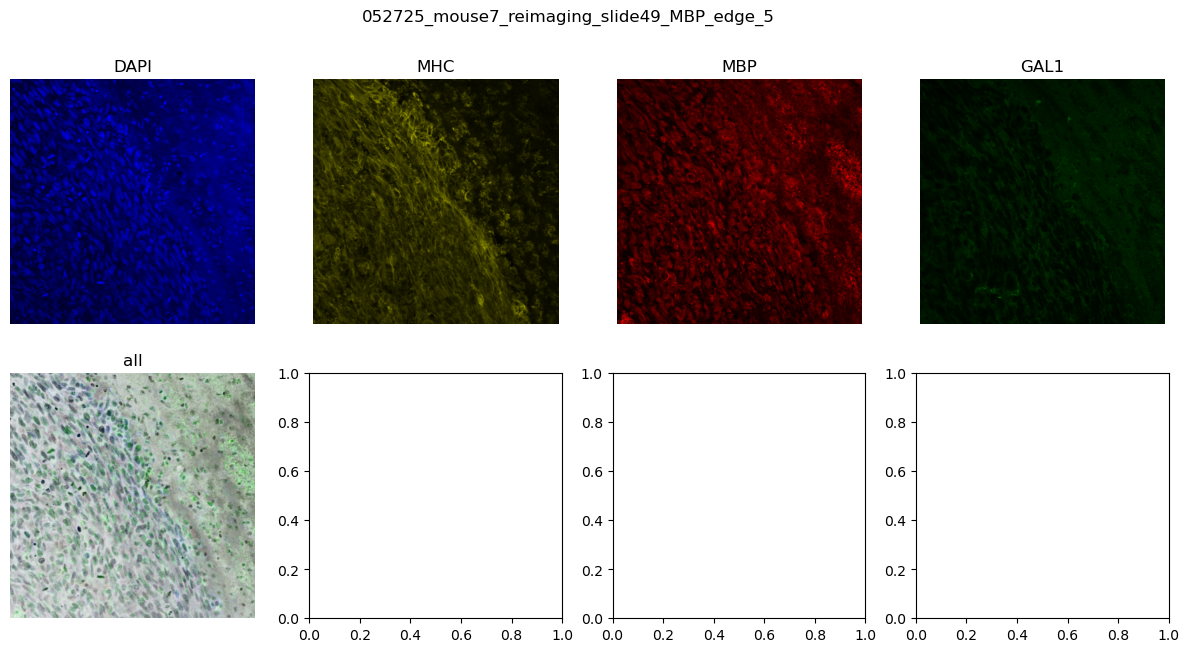

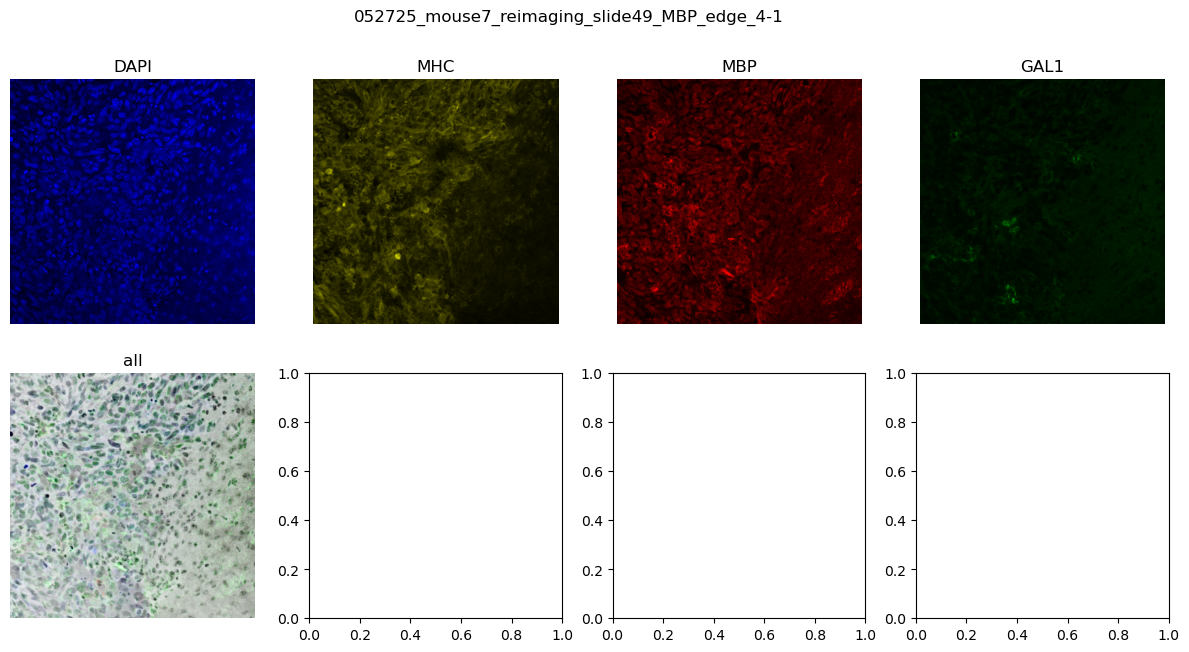

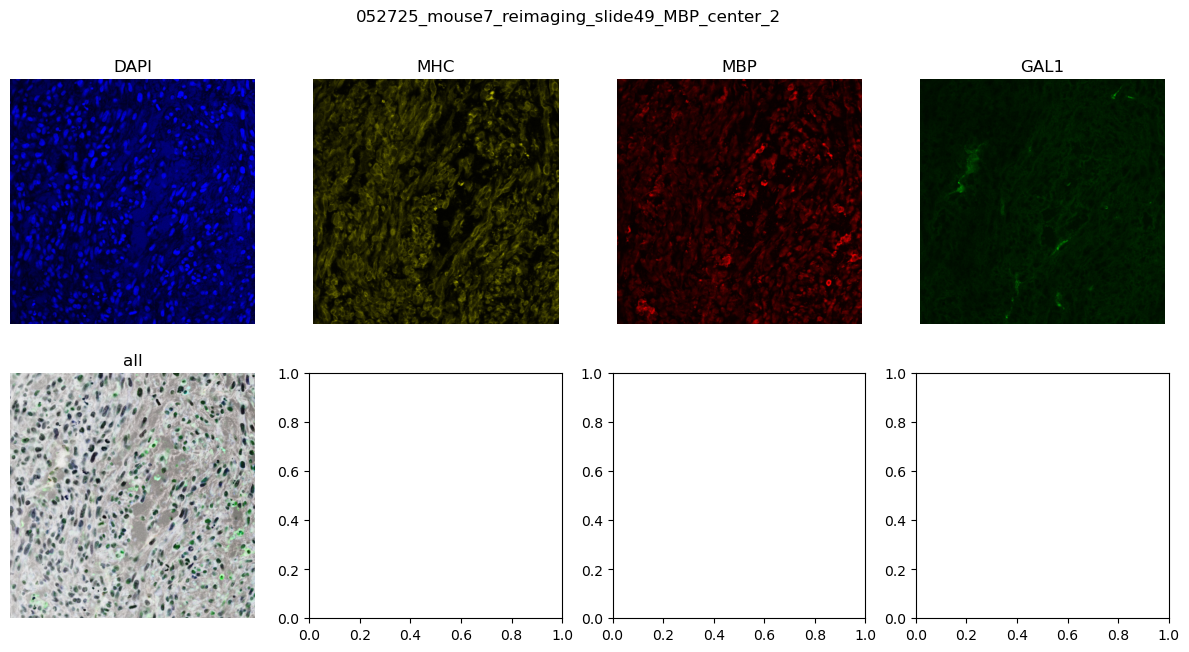

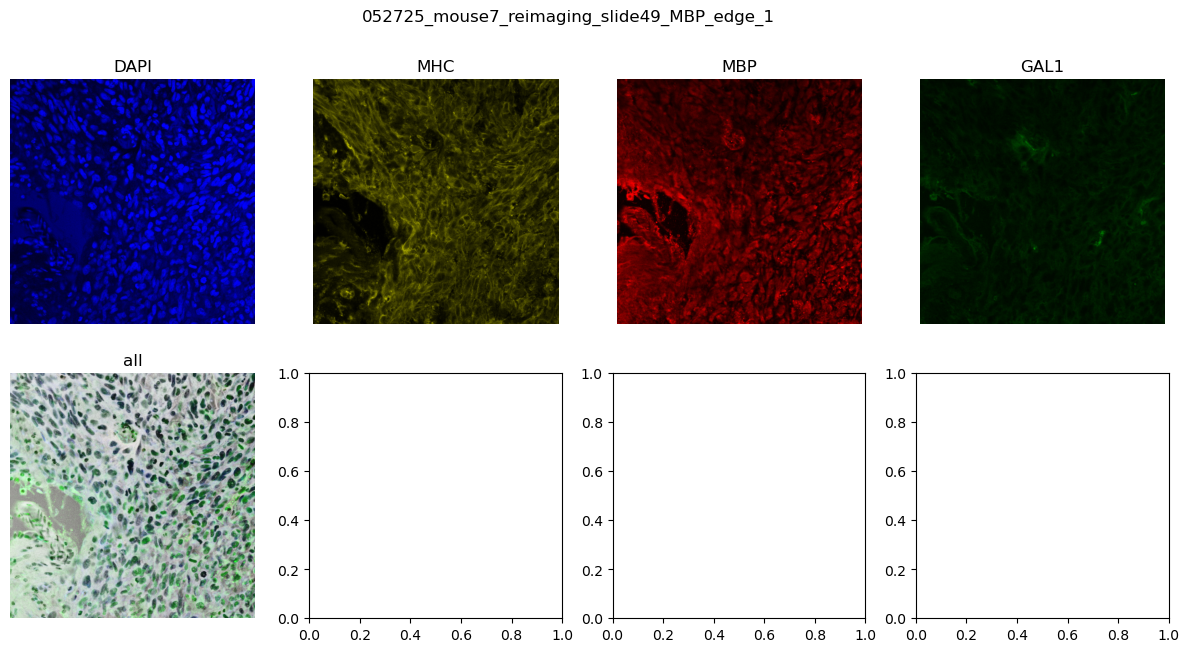

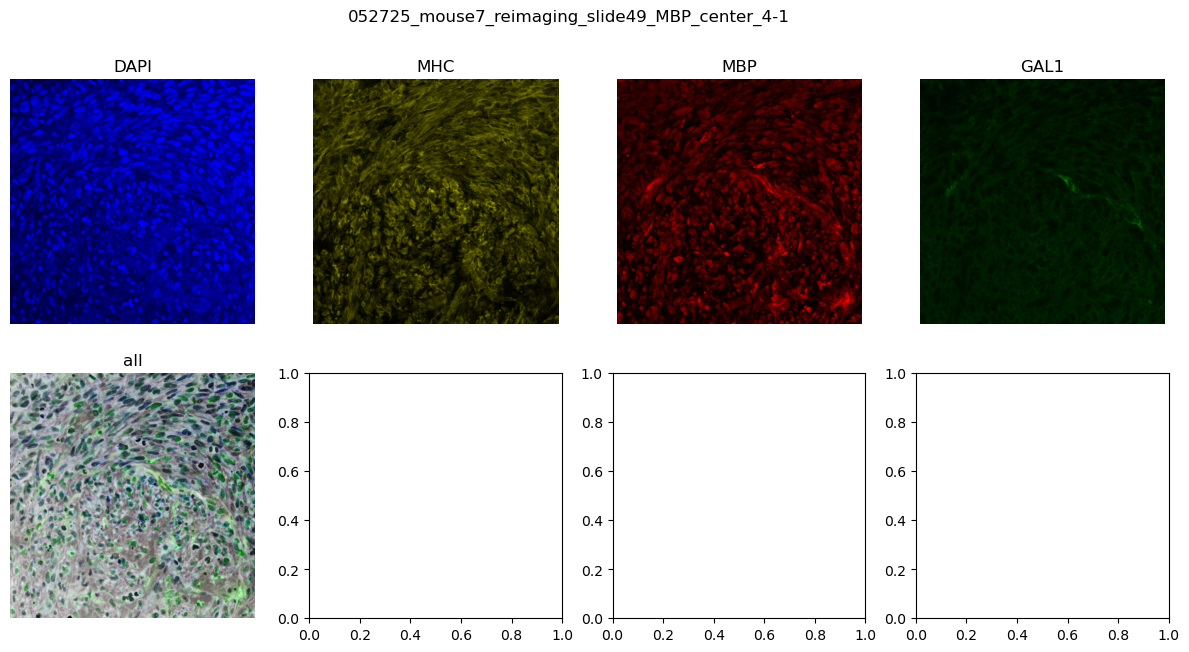

,MBP,GAL1
sample,,
052725_mouse7_reimaging_slide49_MBP_edge_4,0.418936,0.714469
052725_mouse7_reimaging_slide49_MBP_edge_3,0.398544,0.748834
052725_mouse7_reimaging_slide49_MBP_center_4,0.424712,0.392545
052725_mouse7_reimaging_slide49_MBP_center_3,0.46267,0.440633
052725_mouse7_reimaging_slide49_MBP_edge_2,0.444087,0.383069
052725_mouse7_reimaging_slide49_MBP_center_1,0.617825,0.573593
052725_mouse7_reimaging_slide49_MBP_edge_5,0.426261,0.508111
052725_mouse7_reimaging_slide49_MBP_edge_4-1,0.416379,0.718125
052725_mouse7_reimaging_slide49_MBP_center_2,0.243739,0.434603


In [126]:
files_folder = '052726_Reimage/'

for file in os.listdir(files_folder): # loop through each file in the directory
    if os.path.isdir(os.path.join(files_folder, file)): # check if its a file - if not, skip
        sample = file
        img = import_sequence(os.path.join(files_folder, file), channels={'ch00':'DAPI', 'ch01':'MHC', 'ch02':'MBP','ch03':'GAL1'}) # read in file
        img = stack_2d(img) 
        # if you dont want to display each image, change to display=False
        q = area_quant(img, threshold, display=True, title=file) # calculate area
        df.loc[sample, calc_stains] = [q[stain] for stain in calc_stains] # add to our table
df

In [127]:
df.to_csv('052627_Reimage_Mouse7_Gal1_in_mbp.csv')